In [4]:
import torch

from chronos import ChronosPipeline

print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

torch: 2.14.0+xpu
CUDA available: False


In [5]:
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()

print(PROJECT_ROOT)

C:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh


In [6]:
from chronos import ChronosPipeline

pipeline = ChronosPipeline.from_pretrained(
    "amazon/chronos-t5-base",
    device_map="xpu",
    torch_dtype=torch.bfloat16,
)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

In [7]:
print(type(pipeline))
print(next(pipeline.model.model.parameters()).device)
print(next(pipeline.model.model.parameters()).dtype)

<class 'chronos.chronos.ChronosPipeline'>
xpu:0
torch.bfloat16


In [8]:
from pathlib import Path
import numpy as np
from scipy.io import loadmat

PROJECT_ROOT = Path("..").resolve()

mat = loadmat(
    PROJECT_ROOT / "data" / "raw" / "B0005.mat",
    simplify_cells=True
)

cycles = mat["B0005"]["cycle"]

capacities = np.array([
    cycle["data"]["Capacity"]
    for cycle in cycles
    if cycle["type"] == "discharge"
], dtype=float)

soh_0005 = capacities / capacities[0]

context = torch.tensor(
    soh_0005[:64],
    dtype=torch.float32
)

print(context.shape)
print(context[:5])
print(context[-5:])

torch.Size([64])
tensor([1.0000, 0.9945, 0.9886, 0.9886, 0.9882])
tensor([0.9128, 0.9076, 0.9020, 0.9020, 0.8962])


In [9]:
forecast = pipeline.predict(
    context,
    prediction_length=16,
    num_samples=20
)

print("forecast shape:", forecast.shape)

forecast shape: torch.Size([1, 20, 16])


In [10]:
# 20개 sample의 horizon별 median
median_pred = forecast.median(dim=1).values[0].cpu().numpy()

# 실제 future SOH: cycle 65 ~ 80
y_true = soh_0005[64:80]

rmse = np.sqrt(np.mean((y_true - median_pred) ** 2))
mae = np.mean(np.abs(y_true - median_pred))

print("prediction shape:", median_pred.shape)
print()
print("True:")
print(np.round(y_true, 4))
print()
print("Chronos median:")
print(np.round(median_pred, 4))
print()
print(f"RMSE: {rmse:.6f}")
print(f"MAE : {mae:.6f}")

prediction shape: (16,)

True:
[0.8936 0.8909 0.8848 0.8822 0.8795 0.8768 0.8738 0.8679 0.8654 0.8627
 0.8567 0.8542 0.8537 0.8594 0.8482 0.8429]

Chronos median:
[0.8886 0.8886 0.8886 0.8886 0.8815 0.8815 0.8745 0.8745 0.8745 0.8745
 0.8674 0.8674 0.8604 0.8604 0.8533 0.8533]

RMSE: 0.007273
MAE : 0.006212


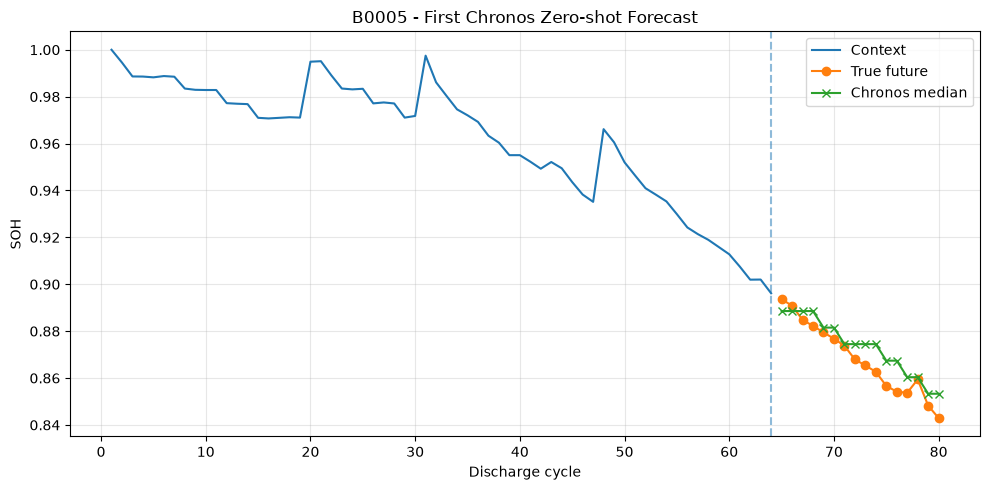

In [11]:
import matplotlib.pyplot as plt

context_x = np.arange(1, 65)
future_x = np.arange(65, 81)

plt.figure(figsize=(10, 5))

plt.plot(
    context_x,
    soh_0005[:64],
    label="Context"
)

plt.plot(
    future_x,
    y_true,
    marker="o",
    label="True future"
)

plt.plot(
    future_x,
    median_pred,
    marker="x",
    label="Chronos median"
)

plt.axvline(64, linestyle="--", alpha=0.5)

plt.xlabel("Discharge cycle")
plt.ylabel("SOH")
plt.title("B0005 - First Chronos Zero-shot Forecast")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
CONTEXT_LENGTH = 64
PREDICTION_LENGTH = 16

def make_windows(series, context_length=64, prediction_length=16):
    X = []
    y = []

    total_length = context_length + prediction_length

    for start in range(len(series) - total_length + 1):
        X.append(series[start:start + context_length])
        y.append(series[start + context_length:start + total_length])

    return np.array(X), np.array(y)

X_0005, y_0005 = make_windows(
    soh_0005,
    CONTEXT_LENGTH,
    PREDICTION_LENGTH
)

print(X_0005.shape, y_0005.shape)

(89, 64) (89, 16)


In [13]:
BATCH_SIZE = 16
NUM_SAMPLES = 20

torch.manual_seed(42)

all_preds = []

for start in range(0, len(X_0005), BATCH_SIZE):
    end = start + BATCH_SIZE

    context_batch = torch.tensor(
        X_0005[start:end],
        dtype=torch.float32
    )

    forecast_batch = pipeline.predict(
        context_batch,
        prediction_length=PREDICTION_LENGTH,
        num_samples=NUM_SAMPLES
    )

    median_batch = (
        forecast_batch
        .median(dim=1)
        .values
        .cpu()
        .numpy()
    )

    all_preds.append(median_batch)

    print(f"{min(end, len(X_0005))}/{len(X_0005)} done")

chronos_pred_0005 = np.concatenate(all_preds, axis=0)

print("prediction shape:", chronos_pred_0005.shape)

16/89 done
32/89 done
48/89 done
64/89 done
80/89 done
89/89 done
prediction shape: (89, 16)


In [14]:
chronos_rmse_0005 = np.sqrt(
    np.mean((y_0005 - chronos_pred_0005) ** 2)
)

chronos_mae_0005 = np.mean(
    np.abs(y_0005 - chronos_pred_0005)
)

print(f"B0005 Chronos RMSE: {chronos_rmse_0005:.6f}")
print(f"B0005 Chronos MAE : {chronos_mae_0005:.6f}")

B0005 Chronos RMSE: 0.013641
B0005 Chronos MAE : 0.009533


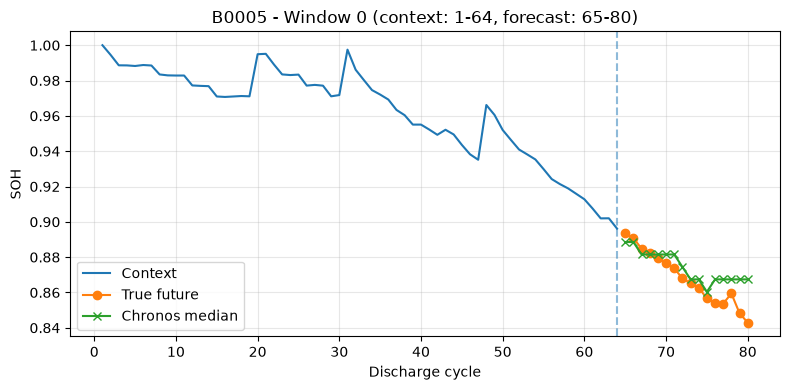

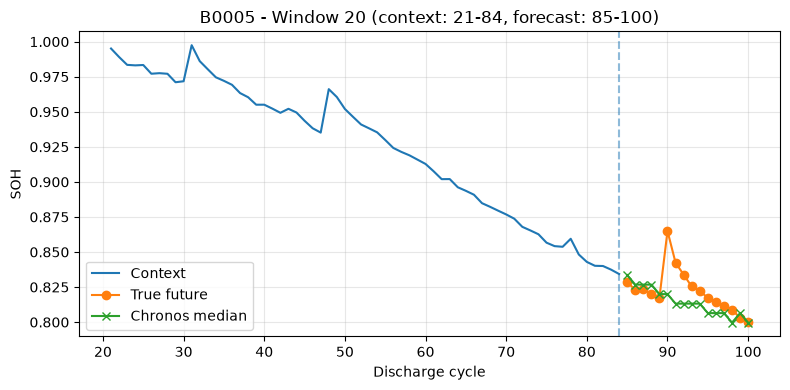

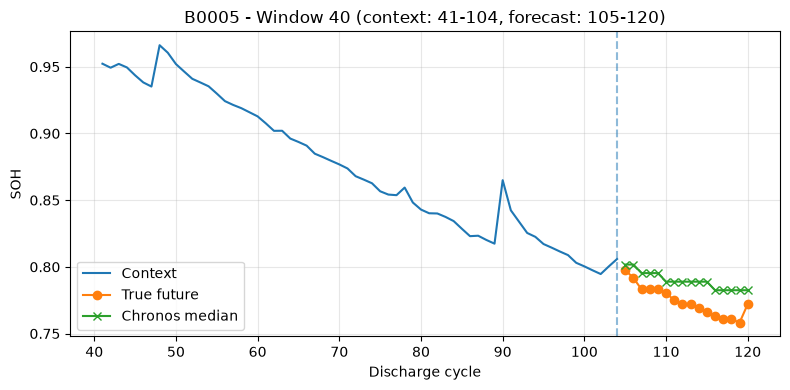

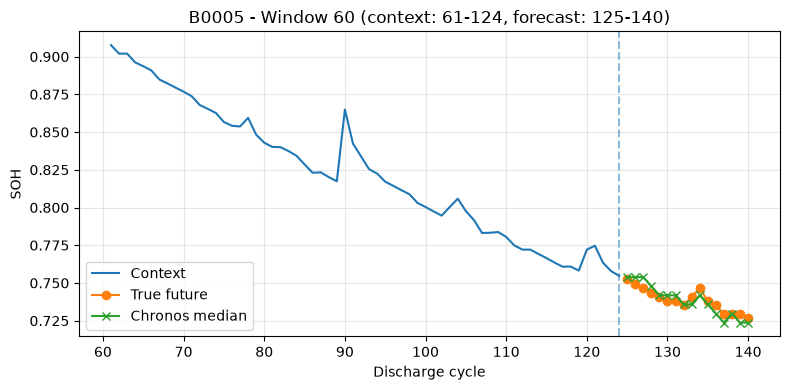

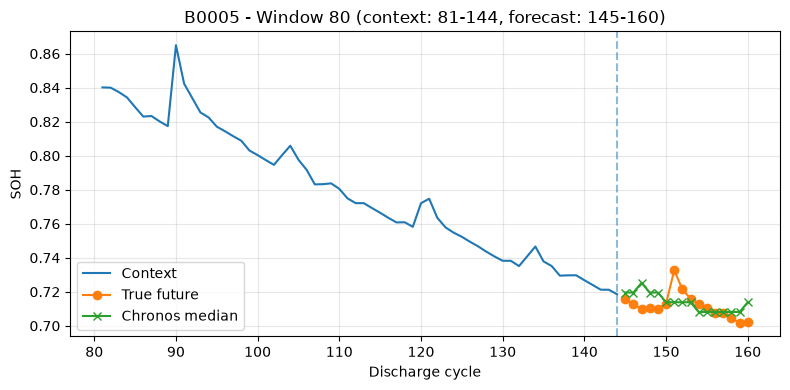

In [15]:
import matplotlib.pyplot as plt
import numpy as np

window_indices = [0, 20, 40, 60, 80]

for idx in window_indices:
    context = X_0005[idx]
    y_true = y_0005[idx]
    y_pred = chronos_pred_0005[idx]

    start_cycle = idx + 1

    x_context = np.arange(start_cycle, start_cycle + CONTEXT_LENGTH)
    x_future = np.arange(
        start_cycle + CONTEXT_LENGTH,
        start_cycle + CONTEXT_LENGTH + PREDICTION_LENGTH
    )

    plt.figure(figsize=(8, 4))
    plt.plot(x_context, context, label="Context")
    plt.plot(x_future, y_true, marker="o", label="True future")
    plt.plot(x_future, y_pred, marker="x", label="Chronos median")
    plt.axvline(x_context[-1], linestyle="--", alpha=0.5)

    plt.title(
        f"B0005 - Window {idx} "
        f"(context: {x_context[0]}-{x_context[-1]}, "
        f"forecast: {x_future[0]}-{x_future[-1]})"
    )
    plt.xlabel("Discharge cycle")
    plt.ylabel("SOH")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [16]:
window_rmse_0005 = np.sqrt(
    np.mean((y_0005 - chronos_pred_0005) ** 2, axis=1)
)

window_mae_0005 = np.mean(
    np.abs(y_0005 - chronos_pred_0005),
    axis=1
)

print(window_rmse_0005.shape, window_mae_0005.shape)

(89,) (89,)


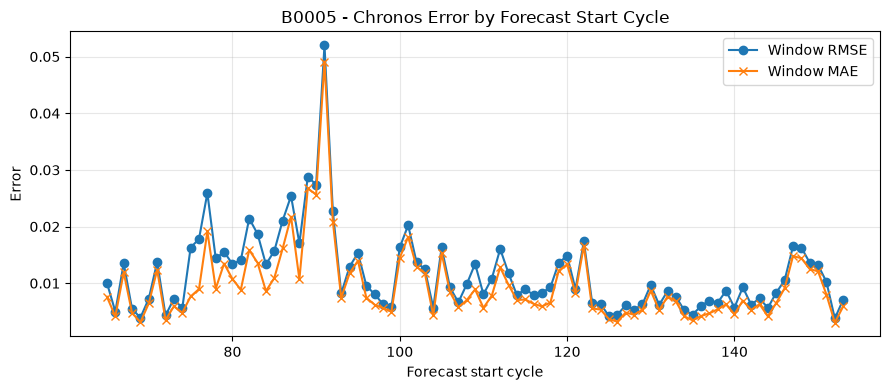

In [17]:
forecast_start_cycles = np.arange(65, 65 + len(window_rmse_0005))

plt.figure(figsize=(9, 4))
plt.plot(
    forecast_start_cycles,
    window_rmse_0005,
    marker="o",
    label="Window RMSE"
)
plt.plot(
    forecast_start_cycles,
    window_mae_0005,
    marker="x",
    label="Window MAE"
)

plt.xlabel("Forecast start cycle")
plt.ylabel("Error")
plt.title("B0005 - Chronos Error by Forecast Start Cycle")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
horizon_rmse = np.sqrt(
    np.mean((y_0005 - chronos_pred_0005) ** 2, axis=0)
)

horizon_mae = np.mean(
    np.abs(y_0005 - chronos_pred_0005),
    axis=0
)


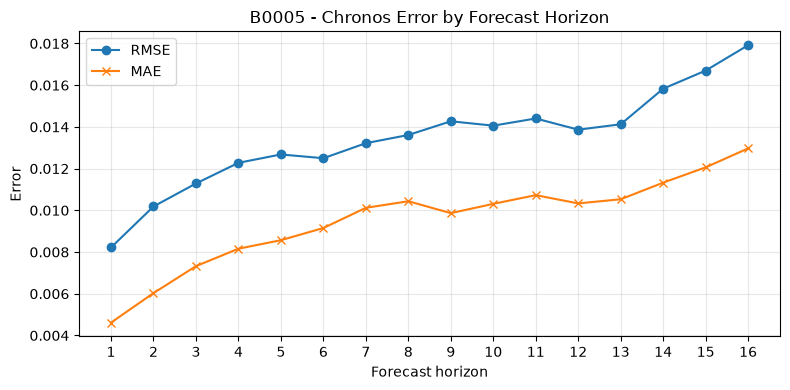

In [19]:
horizons = np.arange(1, PREDICTION_LENGTH + 1)

plt.figure(figsize=(8, 4))

plt.plot(
    horizons,
    horizon_rmse,
    marker="o",
    label="RMSE"
)

plt.plot(
    horizons,
    horizon_mae,
    marker="x",
    label="MAE"
)

plt.xlabel("Forecast horizon")
plt.ylabel("Error")
plt.title("B0005 - Chronos Error by Forecast Horizon")
plt.xticks(horizons)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
battery_ids = ["B0005", "B0006", "B0007", "B0018"]

soh_data = {}

for battery_id in battery_ids:
    mat = loadmat(
        PROJECT_ROOT / "data" / "raw" / f"{battery_id}.mat",
        simplify_cells=True
    )

    cycles = mat[battery_id]["cycle"]

    capacities = np.array([
        cycle["data"]["Capacity"]
        for cycle in cycles
        if cycle["type"] == "discharge"
    ], dtype=float)

    soh_data[battery_id] = capacities / capacities[0]

    print(
        battery_id,
        "cycles:",
        len(soh_data[battery_id])
    )

chronos_results = {
    "B0005": {
        "rmse": 0.013641,
        "mae": 0.009533
    }
}

B0005 cycles: 168
B0006 cycles: 168
B0007 cycles: 168
B0018 cycles: 132


In [21]:
remaining_ids = ["B0006", "B0007", "B0018"]

for battery_id in remaining_ids:
    X, y = make_windows(
        soh_data[battery_id],
        CONTEXT_LENGTH,
        PREDICTION_LENGTH
    )

    all_preds = []

    torch.manual_seed(42)

    for start in range(0, len(X), BATCH_SIZE):
        context_batch = torch.tensor(
            X[start:start + BATCH_SIZE],
            dtype=torch.float32
        )

        forecast_batch = pipeline.predict(
            context_batch,
            prediction_length=PREDICTION_LENGTH,
            num_samples=NUM_SAMPLES
        )

        median_batch = (
            forecast_batch
            .median(dim=1)
            .values
            .cpu()
            .numpy()
        )

        all_preds.append(median_batch)

    y_pred = np.concatenate(all_preds, axis=0)

    battery_rmse = np.sqrt(np.mean((y - y_pred) ** 2))
    battery_mae = np.mean(np.abs(y - y_pred))

    chronos_results[battery_id] = {
        "rmse": battery_rmse,
        "mae": battery_mae
    }

    print(
        f"{battery_id}: "
        f"RMSE={battery_rmse:.6f}, "
        f"MAE={battery_mae:.6f}"
    )

B0006: RMSE=0.019418, MAE=0.013335
B0007: RMSE=0.012504, MAE=0.008332
B0018: RMSE=0.023311, MAE=0.017199


In [22]:
chronos_predictions = {
    "B0005": chronos_pred_0005
}

chronos_targets = {
    "B0005": y_0005
}

remaining_ids = ["B0006", "B0007", "B0018"]

for battery_id in remaining_ids:
    X, y = make_windows(
        soh_data[battery_id],
        CONTEXT_LENGTH,
        PREDICTION_LENGTH
    )

    all_preds = []

    torch.manual_seed(42)

    for start in range(0, len(X), BATCH_SIZE):
        context_batch = torch.tensor(
            X[start:start + BATCH_SIZE],
            dtype=torch.float32
        )

        forecast_batch = pipeline.predict(
            context_batch,
            prediction_length=PREDICTION_LENGTH,
            num_samples=NUM_SAMPLES
        )

        median_batch = (
            forecast_batch
            .median(dim=1)
            .values
            .cpu()
            .numpy()
        )

        all_preds.append(median_batch)

    y_pred = np.concatenate(all_preds, axis=0)

    chronos_predictions[battery_id] = y_pred
    chronos_targets[battery_id] = y

    print(
        battery_id,
        "true:", y.shape,
        "pred:", y_pred.shape
    )

B0006 true: (89, 16) pred: (89, 16)
B0007 true: (89, 16) pred: (89, 16)
B0018 true: (53, 16) pred: (53, 16)


In [23]:
def plot_all_battery_windows(battery_ids):
    fig, axes = plt.subplots(
        len(battery_ids),
        3,
        figsize=(18, 12)
    )

    for row, battery_id in enumerate(battery_ids):
        X, y = make_windows(
            soh_data[battery_id],
            CONTEXT_LENGTH,
            PREDICTION_LENGTH
        )

        y_pred = chronos_predictions[battery_id]

        window_indices = [
            0,
            len(X) // 2,
            len(X) - 1
        ]

        for col, idx in enumerate(window_indices):
            ax = axes[row, col]

            context = X[idx]
            true_future = y[idx]
            pred_future = y_pred[idx]

            window_number = idx + 1

            context_start = idx + 1
            context_end = idx + CONTEXT_LENGTH

            forecast_start = context_end + 1
            forecast_end = context_end + PREDICTION_LENGTH

            context_cycles = np.arange(
                context_start,
                context_end + 1
            )

            future_cycles = np.arange(
                forecast_start,
                forecast_end + 1
            )

            window_rmse = np.sqrt(
                np.mean((true_future - pred_future) ** 2)
            )

            ax.plot(
                context_cycles,
                context,
                label="Context"
            )

            ax.plot(
                future_cycles,
                true_future,
                marker="o",
                label="True future"
            )

            ax.plot(
                future_cycles,
                pred_future,
                marker="x",
                label="Chronos median"
            )

            ax.axvline(
                context_end,
                linestyle="--",
                alpha=0.5
            )

            ax.set_title(
                f"{battery_id} | Window {window_number}\n"
                f"{context_start}-{context_end} → "
                f"{forecast_start}-{forecast_end} | "
                f"RMSE={window_rmse:.4f}"
            )

            ax.set_xlabel("Discharge cycle")
            ax.set_ylabel("SOH")
            ax.grid(alpha=0.3)

            if row == 0 and col == 0:
                ax.legend()

    plt.tight_layout()
    plt.show()

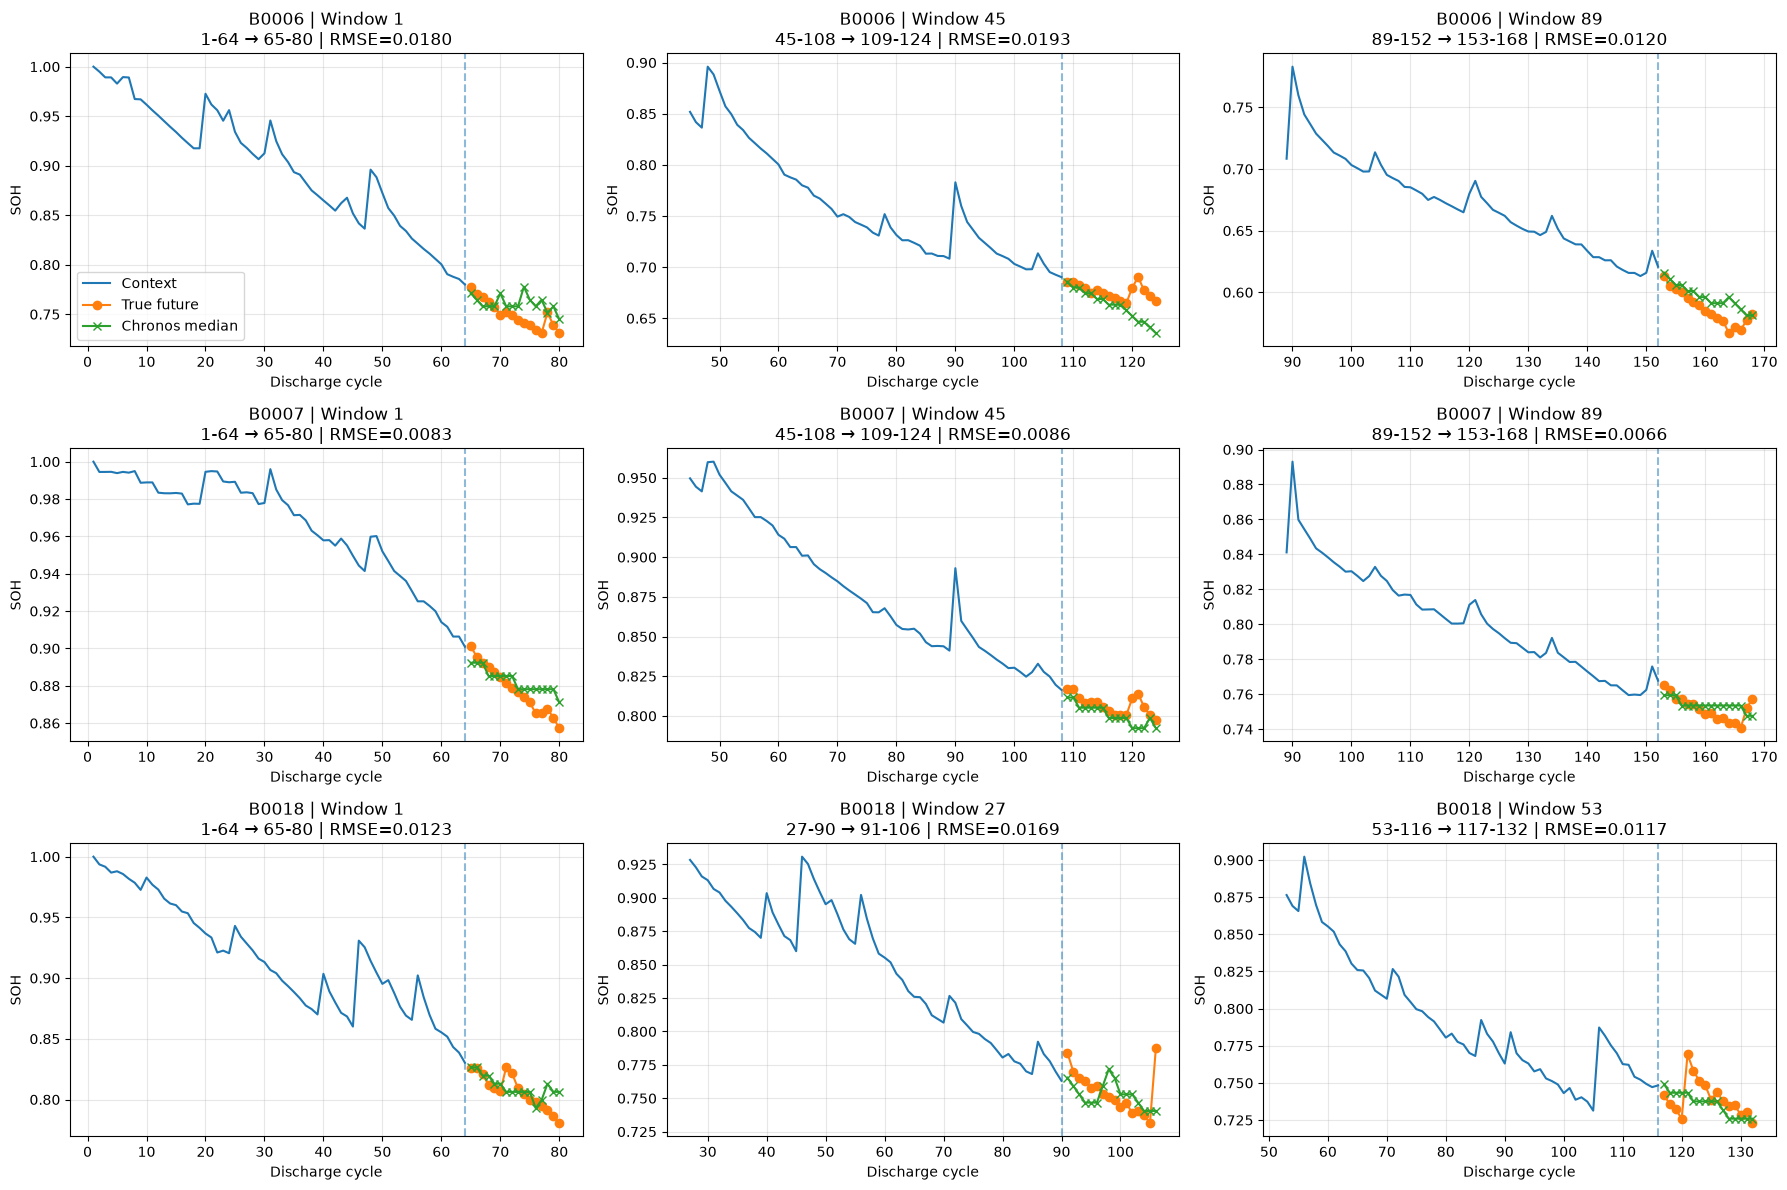

In [24]:
plot_all_battery_windows(
    ["B0006", "B0007", "B0018"]
)

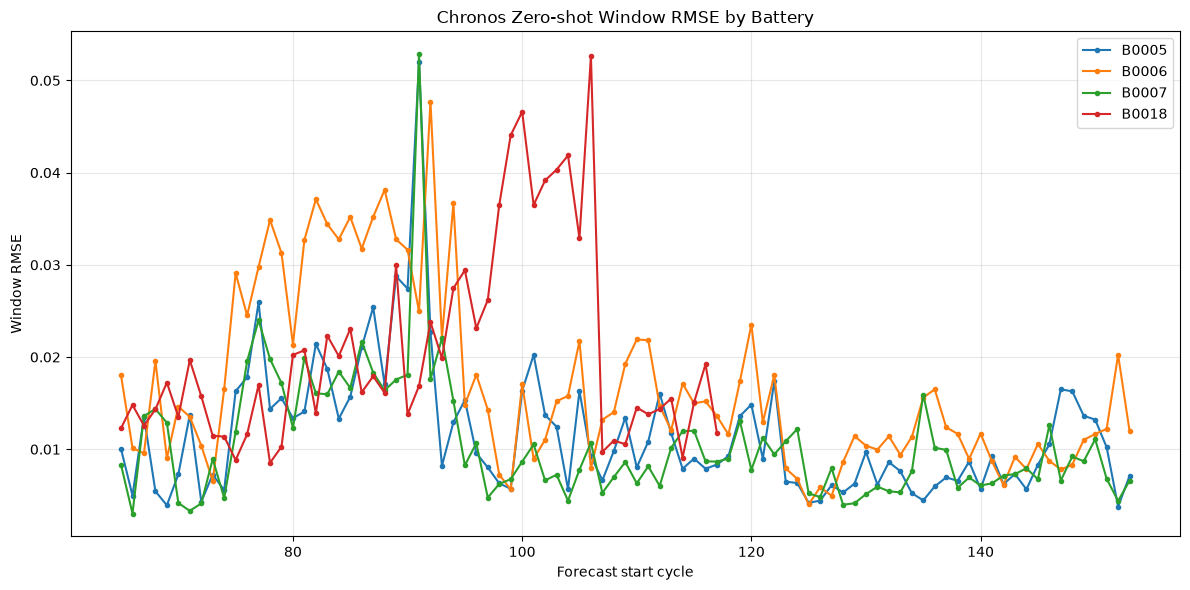

In [25]:
battery_ids = ["B0005", "B0006", "B0007", "B0018"]

plt.figure(figsize=(12, 6))

window_error_data = {}

for battery_id in battery_ids:
    X, y = make_windows(
        soh_data[battery_id],
        CONTEXT_LENGTH,
        PREDICTION_LENGTH
    )

    y_pred = chronos_predictions[battery_id]

    window_rmse = np.sqrt(
        np.mean((y - y_pred) ** 2, axis=1)
    )

    forecast_start_cycles = (
        np.arange(len(window_rmse))
        + CONTEXT_LENGTH
        + 1
    )

    window_error_data[battery_id] = {
        "rmse": window_rmse,
        "forecast_start": forecast_start_cycles
    }

    plt.plot(
        forecast_start_cycles,
        window_rmse,
        marker="o",
        markersize=3,
        label=battery_id
    )

plt.xlabel("Forecast start cycle")
plt.ylabel("Window RMSE")
plt.title("Chronos Zero-shot Window RMSE by Battery")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

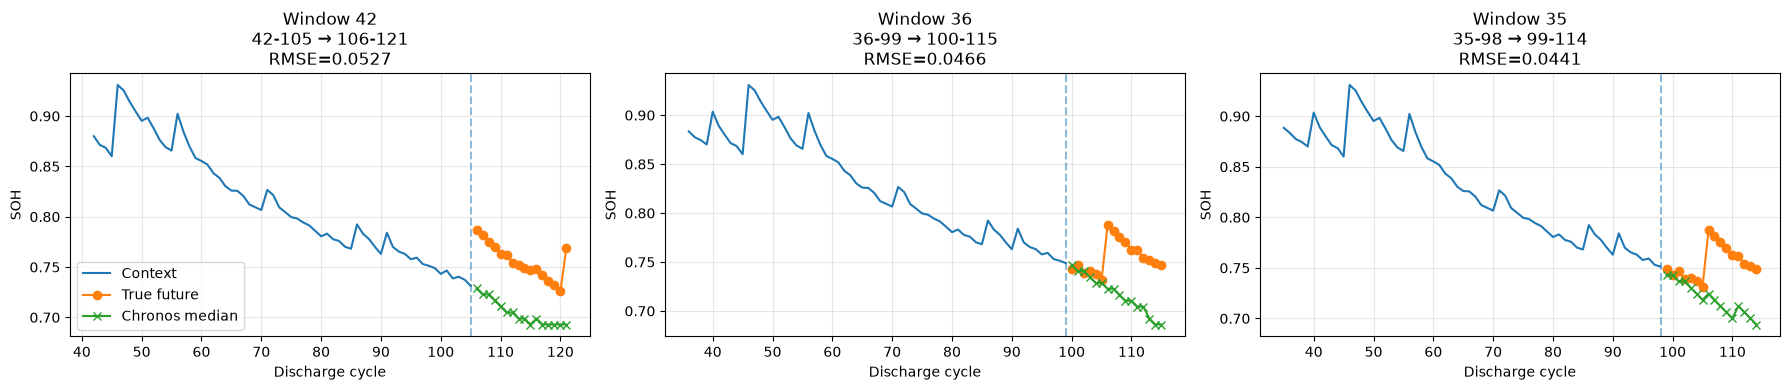

In [26]:
battery_id = "B0018"

X, y = make_windows(
    soh_data[battery_id],
    CONTEXT_LENGTH,
    PREDICTION_LENGTH
)

y_pred = chronos_predictions[battery_id]
rmse_values = window_error_data[battery_id]["rmse"]

worst_indices = np.argsort(rmse_values)[-3:][::-1]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, idx in zip(axes, worst_indices):
    context = X[idx]
    true_future = y[idx]
    pred_future = y_pred[idx]

    context_start = idx + 1
    context_end = idx + CONTEXT_LENGTH

    forecast_start = context_end + 1
    forecast_end = context_end + PREDICTION_LENGTH

    context_cycles = np.arange(
        context_start,
        context_end + 1
    )

    future_cycles = np.arange(
        forecast_start,
        forecast_end + 1
    )

    ax.plot(
        context_cycles,
        context,
        label="Context"
    )

    ax.plot(
        future_cycles,
        true_future,
        marker="o",
        label="True future"
    )

    ax.plot(
        future_cycles,
        pred_future,
        marker="x",
        label="Chronos median"
    )

    ax.axvline(
        context_end,
        linestyle="--",
        alpha=0.5
    )

    ax.set_title(
        f"Window {idx + 1}\n"
        f"{context_start}-{context_end} → "
        f"{forecast_start}-{forecast_end}\n"
        f"RMSE={rmse_values[idx]:.4f}"
    )

    ax.set_xlabel("Discharge cycle")
    ax.set_ylabel("SOH")
    ax.grid(alpha=0.3)

axes[0].legend()

plt.tight_layout()
plt.show()

In [27]:
battery_id = "B0018"
idx = 41   # Window 42 -> Python index 41

X, y = make_windows(
    soh_data[battery_id],
    CONTEXT_LENGTH,
    PREDICTION_LENGTH
)

context = X[idx]
true_future = y[idx]
chronos_pred = chronos_predictions[battery_id][idx]

# Last-value baseline
last_value_pred = np.repeat(
    context[-1],
    PREDICTION_LENGTH
)

# Linear-trend baseline
x_context = np.arange(CONTEXT_LENGTH)
x_future = np.arange(
    CONTEXT_LENGTH,
    CONTEXT_LENGTH + PREDICTION_LENGTH
)

slope, intercept = np.polyfit(
    x_context,
    context,
    deg=1
)

linear_pred = slope * x_future + intercept

# RMSE
rmse_last = np.sqrt(
    np.mean((true_future - last_value_pred) ** 2)
)

rmse_linear = np.sqrt(
    np.mean((true_future - linear_pred) ** 2)
)

rmse_chronos = np.sqrt(
    np.mean((true_future - chronos_pred) ** 2)
)

print(f"Last-value RMSE : {rmse_last:.6f}")
print(f"Linear RMSE     : {rmse_linear:.6f}")
print(f"Chronos RMSE    : {rmse_chronos:.6f}")

Last-value RMSE : 0.030014
Linear RMSE     : 0.054325
Chronos RMSE    : 0.052663


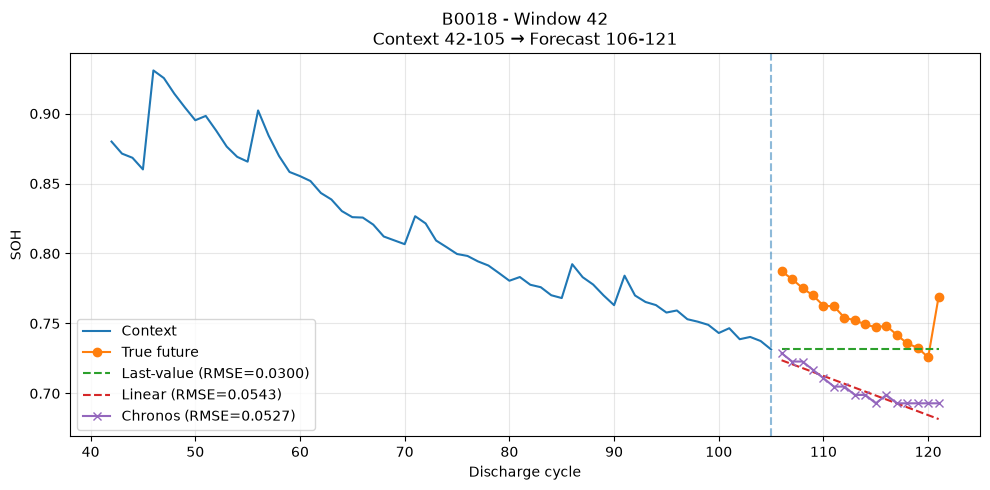

In [28]:
context_start = idx + 1
context_end = idx + CONTEXT_LENGTH

forecast_start = context_end + 1
forecast_end = context_end + PREDICTION_LENGTH

context_cycles = np.arange(
    context_start,
    context_end + 1
)

future_cycles = np.arange(
    forecast_start,
    forecast_end + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    context_cycles,
    context,
    label="Context"
)

plt.plot(
    future_cycles,
    true_future,
    marker="o",
    label="True future"
)

plt.plot(
    future_cycles,
    last_value_pred,
    linestyle="--",
    label=f"Last-value (RMSE={rmse_last:.4f})"
)

plt.plot(
    future_cycles,
    linear_pred,
    linestyle="--",
    label=f"Linear (RMSE={rmse_linear:.4f})"
)

plt.plot(
    future_cycles,
    chronos_pred,
    marker="x",
    label=f"Chronos (RMSE={rmse_chronos:.4f})"
)

plt.axvline(
    context_end,
    linestyle="--",
    alpha=0.5
)

plt.title(
    f"B0018 - Window {idx + 1}\n"
    f"Context {context_start}-{context_end} → "
    f"Forecast {forecast_start}-{forecast_end}"
)

plt.xlabel("Discharge cycle")
plt.ylabel("SOH")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
output_path = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "chronos_zeroshot_predictions.npz"
)

np.savez(
    output_path,
    **chronos_predictions
)

print(output_path)

C:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh\results\metrics\chronos_zeroshot_predictions.npz
